# DX703 Final Project — Final Code Notebook (Part A)

**Due Date:** Sunday, December 6, 2026 at 11:59 p.m. (2-hour, 1-minute grace period)

**No late submissions!**

**Submit:** This completed `.ipynb` notebook and the separate technical report (Part B, `.pdf`).  

## Purpose

Build on your work from the **DX703 Final Project Milestone: Data Exploration and Baseline Modeling**. Using your previously selected dataset and established train/validation/test split, you will:

- Develop and evaluate a custom neural network, including experiments to improve its performance.
- Implement a pretrained model and investigate transfer-learning strategies.
- Compare both approaches with your milestone baseline using validation results.
- Select and finalize the best model based on predictive performance and computational constraints.
- Evaluate the selected model on the held-out test set and analyze its errors.

This assignment supports **both Food-101 (image classification) and HuffPost News Category (text classification)**. Use architectures and preprocessing appropriate to your dataset while addressing the same multiclass-classification objectives.

## Grading Overview

| Problem | Focus | Points |
|---|---|---:|
| 1 | Setup, preprocessing, and baseline recap | **10** |
| 2 | Custom neural network and experiments | **35** |
| 3 | Pretrained model and transfer learning | **35** |
| 4 | Comparison, selection, and final training | **30** |
| 5 | Final test evaluation and error analysis | **25** |
| **Total** | | **135** |

## Important Submission Requirements

- **Preserve the notebook structure.** Complete the provided code and Markdown cells without deleting or replacing them. You may add additional cells as needed. Keep all required results and written responses in their designated locations to support reliable grading without rerunning expensive experiments.

- **Submit a notebook with executed results.** Include the relevant outputs, training histories, comparison tables, metrics, and plots. Code alone is not sufficient evidence for full credit if its required results are missing.

- **Complete the written responses.** Answer questions in the designated Markdown cells, replacing the *Your Answer* placeholders. Provide concise but substantive explanations supported by your experimental results. More extensive discussion belongs in the technical report.

- **Document your experiments.** Use organized, reproducible code, consistent random seeds where practical, and clearly identified model configurations. Avoid hard-coded local paths or dependencies on inaccessible private files.

- **Manage computational constraints responsibly.** You may use documented, reproducible subsets when full-dataset experiments are impractical. Preserve the original train/validation/test separation, explain how subsets were selected, and make model comparisons on consistent or explicitly comparable validation data. Do not present subset results as full-dataset results.

- **Protect the held-out test set.** Use validation results exclusively for model development, tuning, and selection. The final model and evaluation protocol must be fixed in Problem 4 before examining test results in Problem 5. Do not revise the model based on test performance.

- **Preserve expensive experimental results.** You are not required to rerun computationally expensive training during grading. Save the relevant outputs, training configurations, and checkpoints when practical. Your notebook should document how the results were obtained and how the final evaluation could be reproduced.

- **Coordinate with the technical report.** The notebook should demonstrate your implementation, experimental evidence, and concise interpretations. The separate technical report (Part B) will present a more complete discussion of methodology, results, limitations, and conclusions.

## Problem 0 — Dataset Selection (0 pts)

Identify the dataset used for your final project. It must be the same dataset you used in the milestone.

**Selected dataset:** Food-101

## Problem 1 — Setup, Preprocessing, and Baseline Recap (10 pts)

Reuse the dataset, split, and baseline developed in your milestone. You may improve your preprocessing pipeline, but document changes and retain a fair validation comparison. **Do not repeat all the milestone EDA or write another lengthy dataset description.**

- **A. Reusable data pipeline (4 pts)**
- **B. Baseline evidence (4 pts)**
- **C. Milestone-to-final transition (2 pts)**

### Part A — Reusable Data Pipeline (4 pts)

**Implementation (3 pts):**

- Set random seeds;
- import required packages;
- load the chosen dataset or saved splits;
- reuse exactly the established train/validation/test partition;
- implement the final preprocessing/data-loading functions or pipelines needed for modeling.
- Fit learned preprocessing only on training data, and apply training-only augmentation only to training examples.
- **Category consolidation (optional):** You may combine closely related target categories when justified by their meaning (e.g., *Arts* and *Arts and Leisure* in HuffPost). If you consolidated categories in the milestone, preserve that mapping. If you decide to consolidate categories now, apply the mapping consistently across all three splits without changing which observations belong to each split. **Category consolidation is not required.**
- Show split sizes and relevant shape/type sanity checks. **Do not evaluate on the test set.**

**Explanation (1 pt):** Summarize any preprocessing changes relative to the milestone and why they were made. If you consolidated target categories, explain which categories were combined and why. If you changed the category definitions since the milestone, explain how this affects comparisons with your original baseline; models using different category definitions are not directly comparable. If there are no changes, say so.

In [1]:
# ============================================
# Useful Imports
# ============================================

# --- Standard Libraries
import os
import time
import math
import random
from collections import Counter

# --- Core Data / Numerics
import numpy as np
import pandas as pd

# --- Visualization
import matplotlib.pyplot as plt
# import seaborn as sns              # optional
import matplotlib.ticker as mticker  # optional (for formatted axes)

# --- NLP / Tokenization
import spacy                         # used for text preprocessing (HuffPost)

# --- Progress Tracking
from tqdm import tqdm                # optional (nice for loops)

from IPython.display import display

# --- TensorFlow / Keras (Deep Learning)
import tensorflow as tf
from tensorflow.keras import layers, models, Input, callbacks, regularizers, initializers
from tensorflow.keras.callbacks import Callback, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, AdamW
from tensorflow.keras.optimizers.schedules import CosineDecay, ExponentialDecay
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.layers import (
    Dense, Dropout, Flatten, MaxPooling2D, Conv2D,
    SeparableConv2D, GlobalAveragePooling2D, GlobalMaxPooling2D, BatchNormalization,
    MaxPooling2D, Input, Rescaling, RandomFlip, RandomRotation, RandomZoom, RandomContrast,
    RandomBrightness, RandomTranslation, RandomCrop
)
from keras import Sequential

# --- Hugging Face Datasets
from datasets import load_dataset, DatasetDict, Array3D, Features
from datasets.features import ClassLabel

# --- Image operations
from PIL import Image, ImageOps

# --- (Optional) Classical ML Baseline Tools
# from sklearn.pipeline import Pipeline
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.linear_model import LogisticRegression
# from sklearn.metrics import accuracy_score


# ============================================
# Global Configuration & Small Utilities
# ============================================

# Reproducibility
random_seed = 42
random.seed(random_seed)
np.random.seed(random_seed)
tf.keras.utils.set_random_seed(random_seed)   # sets Python, NumPy, and TensorFlow seeds

# Utility: format seconds as HH:MM:SS

"""
Example usage to time your code:

start_time = time.time()
# ... your code here ...
print("Execution Time:", format_hms(time.time() - start_time))
"""

def format_hms(seconds: float) -> str:
    """Convert seconds to HH:MM:SS format."""
    return time.strftime("%H:%M:%S", time.gmtime(seconds))


/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
I0000 00:00:1795048851.909876   41148 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795048852.236465   41148 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795048853.492507   41148 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different compu

In [2]:
food_all = load_dataset("ethz/food101", split="train+validation")  # ~101k images total
label_col = "label"

# Sanity check the label column
assert label_col in food_all.features
assert isinstance(food_all.features[label_col], ClassLabel)

food_label_names = food_all.features[label_col].names
print(f"Total images: {len(food_all):,}  |  Classes: {len(food_label_names)}")

Total images: 101,000  |  Classes: 101


In [3]:
# Duplicate and black/white images identified in EDA
indices_to_remove = {
    18114,  # Keep the first; both prime_rib and steak are valid labels.
    2781,   # Menu photo, not food; hamburger label is incorrect.
    2982,   # Menu photo, not food; hamburger label is incorrect.
    22486,  # Keep the omelette-labeled image; pancake label is incorrect.
    35932,  # Duplicate dumplings image; keep the other copy.
    50919,  # Duplicate pho image; keep the other copy.
    50980,  # Duplicate pho image; keep the other copy.
    99649,  # Duplicate churros image; keep the other copy.
    100572, # Duplicate paella image; keep the other copy.
    18508, # Black and White image
    23754, # Black and White image
    56094 # Black and White image
}

In [4]:
keep_indices = [
    i for i in range(len(food_all))
    if i not in indices_to_remove
]
food_all_clean = food_all.select(keep_indices)

print(f"Removed {len(food_all) - len(food_all_clean)} rows")

Removed 12 rows


In [5]:
label_col = "label"

# Hold out 10% for testing.
temp_split = food_all_clean.train_test_split(
    test_size=0.10,
    seed=42,
    stratify_by_column=label_col,
)

# Split 1/9 of the remaining 90% for validation (10% of the full dataset).
train_val_split = temp_split["train"].train_test_split(
    test_size=1 / 9,
    seed=42,
    stratify_by_column=label_col,
)

food_splits = DatasetDict({
    "train": train_val_split["train"],
    "validation": train_val_split["test"],
    "test": temp_split["test"],
})

for name, split in food_splits.items():
    print(f"{name}: {len(split):,} images")

train: 80,790 images
validation: 10,099 images
test: 10,099 images


In [6]:
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 32
# 128 x 128 (3x less pixels than 224x224 so faster epochs)
IMAGE_SIZE = (128, 128)

# Parallelize workers used by to_tf_dataset to load batches
NUM_WORKERS = 4

# Hugging Face .map() passes one example dictionary at a time.
# Keep this step deterministic; random augmentation belongs in the
# TensorFlow training pipeline so it can vary across epochs.
def preprocess_example(example):
    # 1. Ensure each row is already in RGB (We already have checked this at this point but it is a safe cast)
    image = example["image"].convert("RGB")

    # 2. Resize and Crop
    image = ImageOps.fit(image, IMAGE_SIZE, method=Image.Resampling.BILINEAR)

    return {
        "image": np.asarray(image, dtype=np.uint8),
        "label": int(example["label"]),
    }

# Tell Hugging Face the fixed shape and type of the processed images.
processed_features = Features({
    "image": Array3D(shape=(128, 128, 3), dtype="uint8"),
    "label": food_splits["train"].features["label"],
})

# Apply the deterministic preprocessing to each existing split.
# The split names remain "train", "validation", and "test".
processed_splits = food_splits.map(
    preprocess_example,
    remove_columns=food_splits["train"].column_names,
    features=processed_features,
)


def make_tf_dataset(split, *, training=False):
    # Keep images uint8 (0-255 all the way through the tf.data pipeline. Float32 is 4x larger)
    return split.to_tf_dataset(
        columns=['image'],
        label_cols=['label'],
        batch_size=BATCH_SIZE,
        shuffle=training,
        num_workers=NUM_WORKERS,
        prefetch=True
    )

train_ds = make_tf_dataset(processed_splits["train"], training=True)
val_ds = make_tf_dataset(processed_splits["validation"])
test_ds = make_tf_dataset(processed_splits["test"])

/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/datasets/arrow_dataset.py:410: FutureWarning: The output of `to_tf_dataset` will change when a passing single element list for `labels` or `columns` in the next datasets version. To return a tuple structure rather than dict, pass a single string.
Old behaviour: columns=['a'], labels=['labels'] -> (tf.Tensor, tf.Tensor)  
             : columns='a', labels='labels' -> (tf.Tensor, tf.Tensor)  
New behaviour: columns=['a'],labels=['labels'] -> ({'a': tf.Tensor}, {'labels': tf.Tensor})  
             : columns='a', labels='labels' -> (tf.Tensor, tf.Tensor) 
  warnings.warn(
I0000 00:00:1795048856.440010   41148 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5527 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Ti, pci bus id: 0000:01:00.0, compute capability: 8.9


In [7]:
preprocessing_layers = Sequential([
    Rescaling(1.0 / 255), # uint8 [0,255] to float32 [0,1]
    RandomFlip("horizontal"),
    RandomBrightness(0.1, value_range=(0.0, 1.0)),
    RandomContrast(0.1),
], name='preprocessing_layers')

In [8]:
def plot_learning_curves(hist, title, verbose=True):
    
    val_losses = hist.history['val_loss']
    min_val_loss = min(val_losses)
    min_val_epoch = val_losses.index(min_val_loss)
    val_acc_at_min_loss = hist.history['val_accuracy'][min_val_epoch]

    epochs = range(1, len(val_losses) + 1)  # epoch numbers starting at 1

    fig, axs = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

    # --- Loss Plot ---
    axs[0].plot(epochs, hist.history['loss'], label='train loss')
    axs[0].plot(epochs, hist.history['val_loss'], label='val loss')
    axs[0].scatter(min_val_epoch + 1, min_val_loss, color='red', marker='x', s=50, label='min val loss')
    axs[0].set_title(f'{title} - Categorical Cross-Entropy Loss')
    axs[0].set_ylabel('Loss')
    axs[0].legend()
    axs[0].grid(True)

    # --- Accuracy Plot ---
    axs[1].plot(epochs, hist.history['accuracy'], label='train acc')
    axs[1].plot(epochs, hist.history['val_accuracy'], label='val acc')
    axs[1].scatter(min_val_epoch + 1, val_acc_at_min_loss, color='red', marker='x', s=50, label='acc @ min val loss')
    axs[1].set_title(f'{title} - Accuracy')
    axs[1].set_xlabel('Epoch')
    axs[1].set_ylabel('Accuracy')
    axs[1].legend()
    axs[1].grid(True)
    axs[1].set_ylim(0, 1.05)

    plt.tight_layout()
    plt.show()

    if verbose:
        print(f"Final Training Loss:            {hist.history['loss'][-1]:.4f}")
        print(f"Final Training Accuracy:        {hist.history['accuracy'][-1]:.4f}")
        print(f"Final Validation Loss:          {hist.history['val_loss'][-1]:.4f}")
        print(f"Final Validation Accuracy:      {hist.history['val_accuracy'][-1]:.4f}")
        print(f"Minimum Validation Loss:        {min_val_loss:.4f} (Epoch {min_val_epoch + 1})")
        print(f"Validation Accuracy @ Min Loss: {val_acc_at_min_loss:.4f}")

    results[title] = (val_acc_at_min_loss,min_val_epoch + 1)

results = {}

def print_results():
    for title, (acc, ep) in sorted(results.items(), 
                                   key=lambda kv: kv[1][0],   # kv[1] is (acc, epoch); [0] is acc
                                   reverse=True
                                  ):
        print(f"{title:<40}\t{acc:.4f}\t{ep}")

# Uses globals: train_ds, val_ds, test_ds

def train_and_test(model, 
                   epochs        = 500,
                   lr_schedule   = 1e-3,
                   optimizer     = "Adam",
                   title         = "Learning Curves",
                   use_early_stopping = True,
                   patience      = 5,
                   min_delta     = 0.0001,
                   callbacks     = [],
                   verbose       = 0,
                   return_history = False,
                   evaluate_test_set = False
                  ):

    print(f"\n{title}\n")

    # Choose optimizer
    if optimizer == "Adam":
        opt = Adam(learning_rate=lr_schedule)
    else:
        opt = optimizer

    # Compile
    model.compile(
        optimizer=opt,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=patience,
        min_delta=min_delta,
        restore_best_weights=True,
        verbose=verbose
    )

    cbs = ([early_stop] if use_early_stopping else []) + callbacks

    start = time.time()

    # Fit on tf.data datasets (already batched)
    history = model.fit(
        train_ds,
        epochs=epochs,
        validation_data=val_ds,
        callbacks=cbs,
        verbose=verbose
    )

    # Determine best validation accuracy
    if use_early_stopping and hasattr(early_stop, "best_epoch") and early_stop.best_epoch is not None:
        best_epoch = early_stop.best_epoch
        best_acc   = history.history['val_accuracy'][best_epoch]
    else:
        best_epoch = int(np.argmax(history.history['val_accuracy']))
        best_acc   = history.history['val_accuracy'][best_epoch]

    plot_learning_curves(history, title=title)

    # Evaluate on tf.data test set
    if evaluate_test_set:
        test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)

        print(f"\nTest Loss: {test_loss:.4f}")
        print(f"Test Accuracy: {test_accuracy:.4f}")
        print(f"\nValidation-Test Gap (accuracy): {abs(best_acc - test_accuracy):.6f}")

    end = time.time()
    print(f"\nExecution Time: " + format_hms(end-start))

    if return_history:
        return history


**Your Answer:**

> Summarize any preprocessing changes relative to the milestone and why they were necessary. If there are no changes, say so.

I did not make any preprocessing changes relative to the milestone. I retained the cleaning steps to remove black and white and duplicate images. I also retained the same
preprocessing pipeline.

### Part B — Recover the Milestone Baseline (4 pts)

**Evidence (3 pts):** 

- Supply the baseline architecture/configuration and its previously obtained validation results, including the principal selection metric.
- Include training history or relevant plots where applicable.
- Reuse saved milestone results where practical; baseline retraining is not required solely for this section.

**Explanation (1 pt):** State the baseline's primary limitation and the validation metric that will be used to compare later models. Keep metric definitions and validation samples consistent across comparisons.

In [9]:
he = initializers.HeNormal()
num_classes = 101

baseline_model = Sequential([
    Input(shape=(*IMAGE_SIZE, 3)), # 128x128 with 3 channels (RGB)
    preprocessing_layers,  # rescale + augment during training
    Conv2D(32, (3,3), activation="relu", kernel_initializer=he, padding="same"),
    MaxPooling2D(),
    GlobalAveragePooling2D(),  # (64, 64, 32) -> (64,)

    # Compact head
    Dense(128, activation='relu', kernel_initializer=he),
    Dense(num_classes, activation='softmax')
])


Baseline Model



/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1794959388.606499    3301 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1794959389.712217    4439 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794959390.059660    4441 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment v

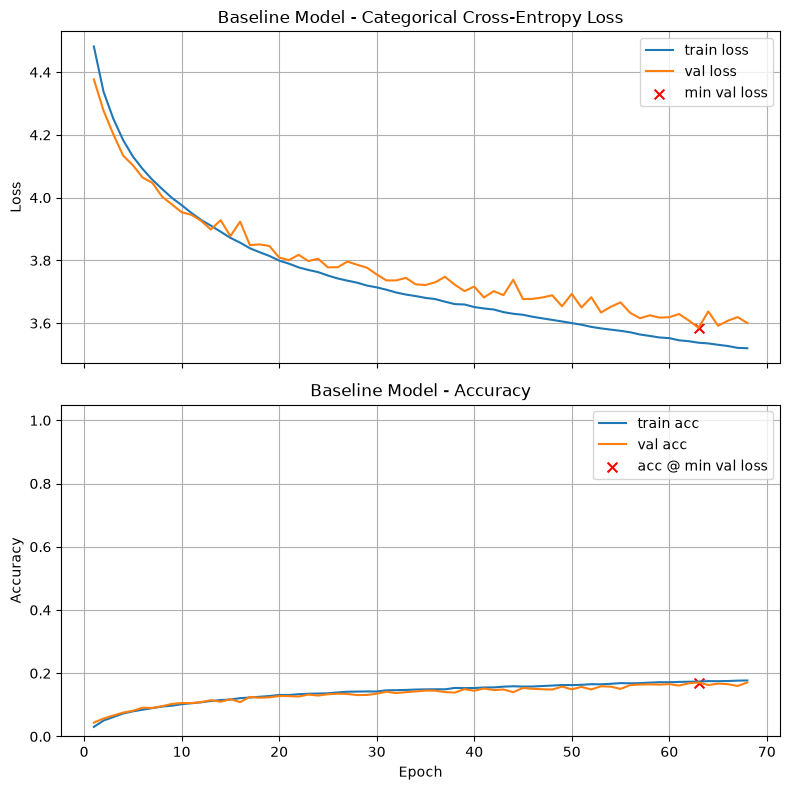

Final Training Loss:            3.5202
Final Training Accuracy:        0.1772
Final Validation Loss:          3.6005
Final Validation Accuracy:      0.1708
Minimum Validation Loss:        3.5853 (Epoch 63)
Validation Accuracy @ Min Loss: 0.1706

Execution Time: 00:32:24


In [12]:
baseline_history = train_and_test(baseline_model, title="Baseline Model", verbose=0, return_history=True)

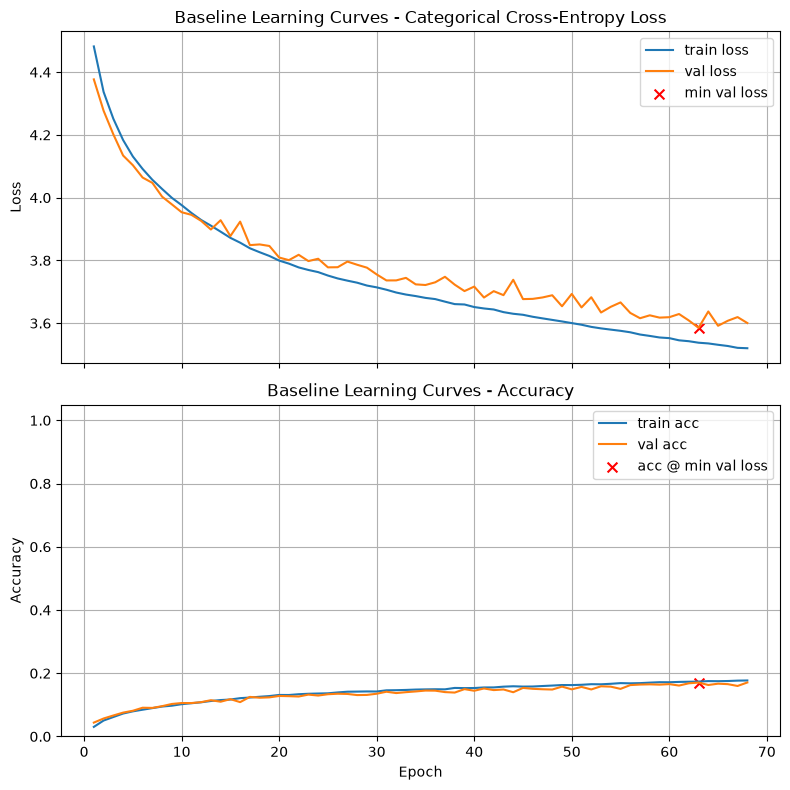

Final Training Loss:            3.5202
Final Training Accuracy:        0.1772
Final Validation Loss:          3.6005
Final Validation Accuracy:      0.1708
Minimum Validation Loss:        3.5853 (Epoch 63)
Validation Accuracy @ Min Loss: 0.1706


In [13]:
plot_learning_curves(baseline_history, "Baseline Learning Curves")

**Your Answer:**

> State the baseline's primary limitation and the validation metric that will be used to compare later models. Keep metric definitions and validation samples consistent across comparisons.

*Replace this line with your response.*

### Part C — Plan the Final Experiments (2 pts)

- Briefly describe your experimental plan for developing and comparing the custom and pretrained models.
- Identify the improvements or alternatives you intend to investigate, any practical constraints (data subset, training time, compute resources);
    - Include how you will ensure fair comparisons using consistent validation data and metrics.
- Do not use the test set for model selection.

**Your Answer:**

*Replace this text with your answer.*

## Problem 2 — Custom Neural Network and Experiments (35 pts)

- Design and train a more capable, non-pretrained neural network than the milestone baseline, using an architecture appropriate to your dataset.
- Perform at least **two documented runs/configurations** (an initial custom design and at least one intentional improvement experiment).
- The experiments should test a meaningful hypothesis, not merely change a random seed.
- Compare using **validation only**.

> **A. Architecture and implementation (12 pts)**    
> **B. Training and controlled improvement experiment (13 pts)**    
> **C. Results and interpretation (10 pts)**

### Part A — Design and Implement a Custom Model (12 pts)

**Implementation (9 pts):**
- Define and build a custom multiclass neural network trained from scratch (no pretrained weights).
- Present the model architecture, including input representation, principal layers, output layer, regularization, and model summary or equivalent.
- Design an architecture with greater representational capacity or more appropriate inductive biases than the milestone baseline.
- Clearly distinguish model components from preprocessing components.

**Rationale (3 pts):** Explain the principal architectural differences from the milestone baseline, why you chose this design, and how you expect these changes to improve representation learning or generalization.

In [12]:
def conv_block(filters):
    return [
        Conv2D(filters, 3, activation="relu", kernel_initializer=he, padding="same"),
        BatchNormalization(),
        MaxPooling2D()
    ]

custom_model = Sequential([
    Input(shape=(*IMAGE_SIZE, 3)), # 128x128 with 3 channels (RGB)
    preprocessing_layers,  # rescale + augment during training
    *conv_block(32),
    *conv_block(64),
    *conv_block(128),
    GlobalAveragePooling2D(),
    Dropout(0.4),

    # Compact head
    Dense(128, activation='relu', kernel_initializer=he),
    Dense(num_classes, activation='softmax')
])

**Your Answer:**

> Explain the principal architectural differences from the milestone baseline, why you chose this design, and how you expect these changes to improve representation learning or generalization.

*Replace this line with your response.*

### Part B — Train and Run a Targeted Improvement Experiment (13 pts)

**Implementation (10 pts):**

- Train the initial custom model and at least one **deliberate variant**.
  - Examples include a justified change to model capacity, regularization, augmentation, optimizer/learning rate, or learning-rate scheduling.
- Document the training configuration for each run, including loss function, optimizer, learning rate, batch size, number of epochs, and any regularization or callbacks used.
- Set reproducible configurations and use a validation-based stopping/selection strategy where appropriate.
- Record training and validation learning curves, the number of epochs actually completed, validation metrics, and approximate training time for each run.
- Use consistent validation data and a clearly stated primary metric to ensure fair comparisons.

**Experiment statement (3 pts):** State the **hypothesis** motivating your improvement experiment, identify what changed between configurations, and explain the expected benefit and any trade-offs. Your hypothesis should be independent of the observed results. **Do not use the test set.**

### Train the Custom Model


Custom Model



/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795051502.040362   54379 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795051502.425573   54381 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/requests/__init__.py:92

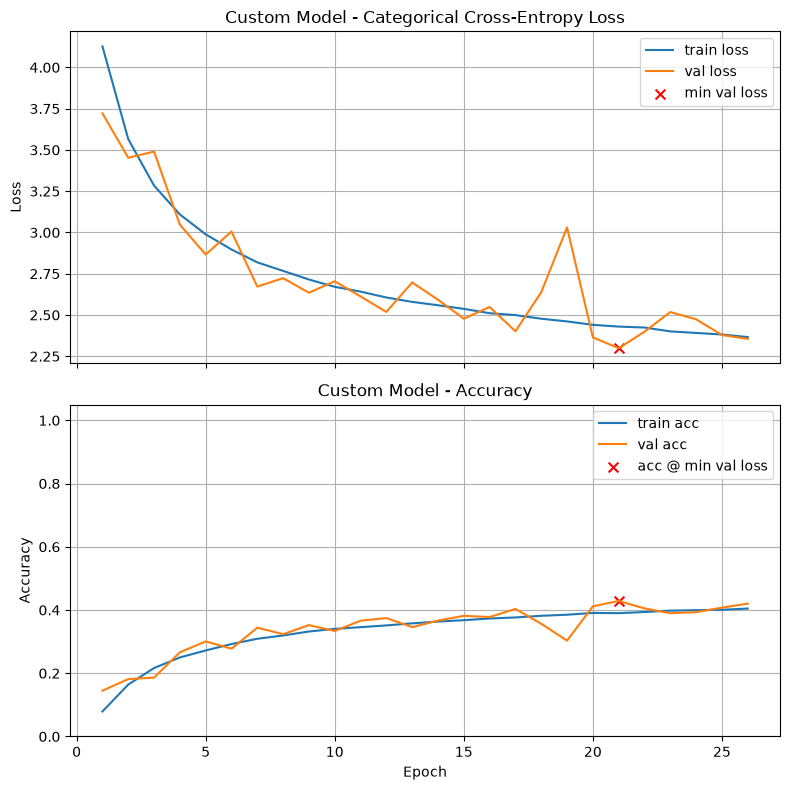

Final Training Loss:            2.3664
Final Training Accuracy:        0.4047
Final Validation Loss:          2.3557
Final Validation Accuracy:      0.4202
Minimum Validation Loss:        2.2988 (Epoch 21)
Validation Accuracy @ Min Loss: 0.4288

Execution Time: 00:21:28


In [13]:
custom_model_history = train_and_test(custom_model, title="Custom Model", verbose=0, return_history=True)

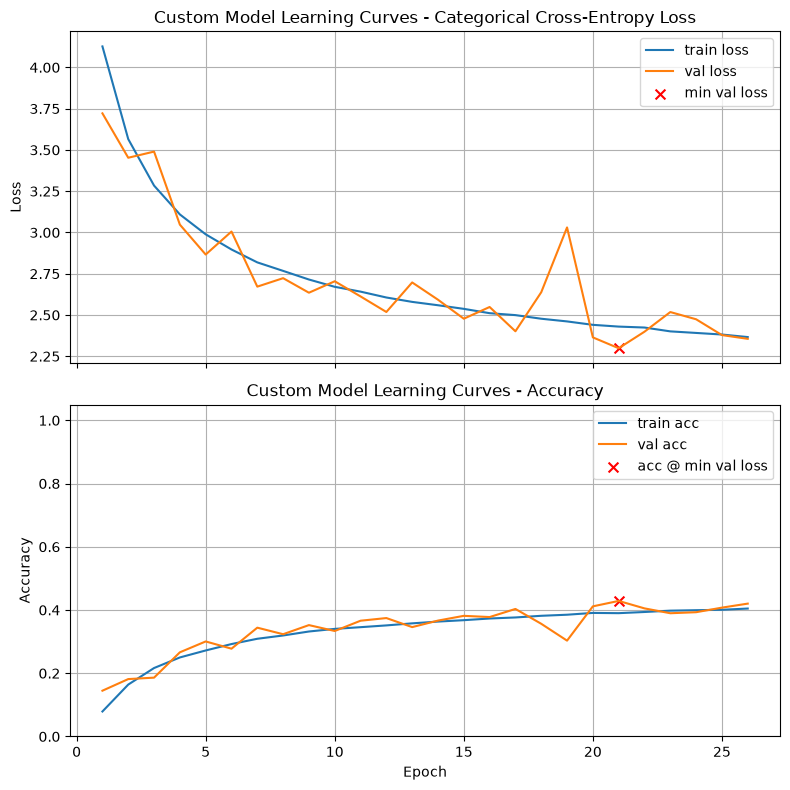

Final Training Loss:            2.3664
Final Training Accuracy:        0.4047
Final Validation Loss:          2.3557
Final Validation Accuracy:      0.4202
Minimum Validation Loss:        2.2988 (Epoch 21)
Validation Accuracy @ Min Loss: 0.4288


In [14]:
plot_learning_curves(custom_model_history, "Custom Model Learning Curves")

### Train a variant

In [15]:
def conv_block_v2(filters):
    return [
        Conv2D(filters, 3, activation="relu", kernel_initializer=he, padding="same"),
        BatchNormalization(),
        Conv2D(filters, 3, activation="relu", kernel_initializer=he, padding="same"),
        BatchNormalization(),
        MaxPooling2D()
    ]

custom_model_v2 = Sequential([
    Input(shape=(*IMAGE_SIZE, 3)), # 128x128 with 3 channels (RGB)
    preprocessing_layers,  # rescale + augment during training
    *conv_block_v2(32),
    *conv_block_v2(64),
    *conv_block_v2(128),
    GlobalAveragePooling2D(),
    Dropout(0.4),

    # Compact head
    Dense(128, activation='relu', kernel_initializer=he),
    Dense(num_classes, activation='softmax')
])


Custom Model V2



I0000 00:00:1795053954.028356   65708 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795053954.397007   65716 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
I0000 00:00:1795053954.791011   65718 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn 

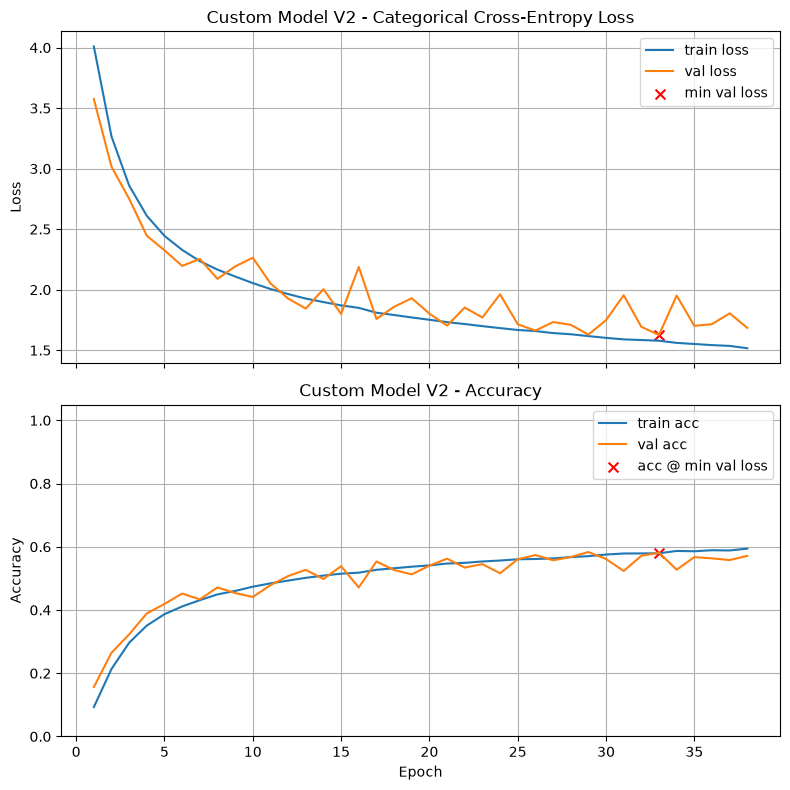

Final Training Loss:            1.5164
Final Training Accuracy:        0.5942
Final Validation Loss:          1.6842
Final Validation Accuracy:      0.5713
Minimum Validation Loss:        1.6260 (Epoch 33)
Validation Accuracy @ Min Loss: 0.5813

Execution Time: 00:52:30


In [16]:
custom_model_v2_history = train_and_test(custom_model_v2, title="Custom Model V2", verbose=0, return_history=True)

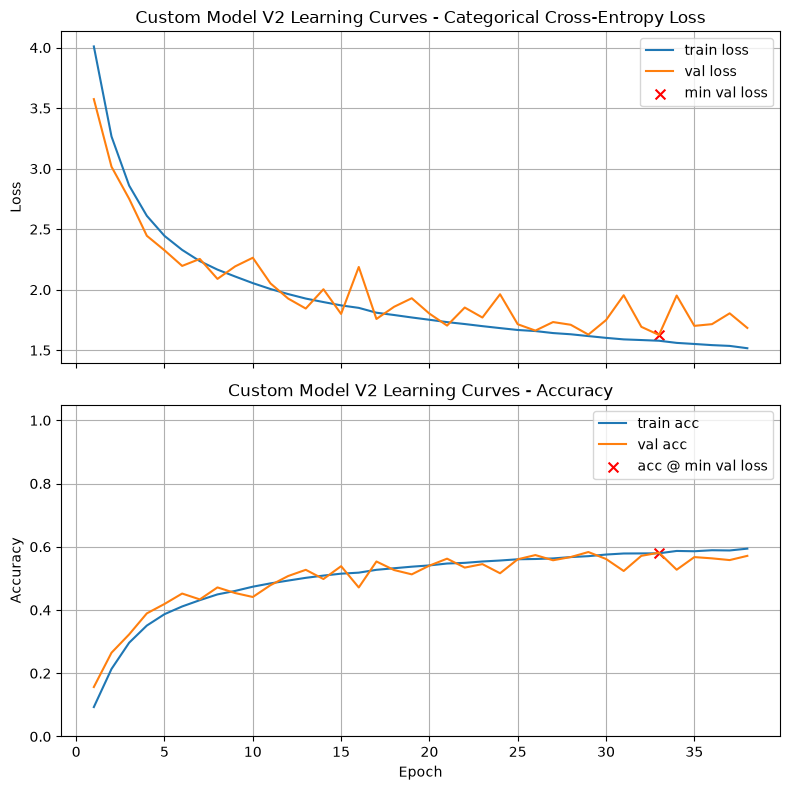

Final Training Loss:            1.5164
Final Training Accuracy:        0.5942
Final Validation Loss:          1.6842
Final Validation Accuracy:      0.5713
Minimum Validation Loss:        1.6260 (Epoch 33)
Validation Accuracy @ Min Loss: 0.5813


In [17]:
plot_learning_curves(custom_model_v2_history, "Custom Model V2 Learning Curves")

**Your Answer:**

> State the hypothesis motivating your improvement experiment, identify what changed between configurations, and explain the expected benefit and any trade-offs.

*Replace this text with your answer.*

### Part C — Analyze Custom Model Results (10 pts)

**Results (6 pts):**

- Present an organized, side-by-side **validation comparison** of the milestone baseline, initial custom network, and improved custom network.
  - Include the primary selection metric, at least one supporting metric, and relevant training/validation learning curves.
  - Clearly identify the experimental configurations being compared.
- Identify the best custom configuration using the previously declared selection metric. **Do not use test results for model selection.**

**Interpretation (4 pts):**

- Evaluate whether your improvement hypothesis was supported by the validation results, citing specific evidence.
- Discuss evidence of underfitting or overfitting, generalization, and any trade-offs between model performance and computational cost.
- Explain what you learned about model architecture, training, or optimization and how these findings will inform your subsequent experiments.
- If the custom models did not outperform the milestone baseline, explain what the results suggest rather than concealing or dismissing the outcome.

In [9]:
# P2.C — Compare validation results.
# Create a table comparing the milestone baseline,
# initial custom network, and improved custom network.
# Include configurations and validation metrics.

# YOUR CODE HERE


In [10]:
# P2.C — Visualize training and validation behavior.
# Plot clearly labeled learning curves for the custom models.
# Include any additional plots useful for interpreting
# generalization, underfitting, or overfitting.

# YOUR CODE HERE


**Interpretation: Your Answer:**

*Replace this text with your answer.*

## Problem 3 — Pretrained Models and Transfer Learning (35 pts)

In this problem, you will investigate whether **transfer learning** can improve performance on your classification task. Select an appropriate pretrained model, adapt it to your dataset, and evaluate different strategies for using its pretrained representations.

You will:

- Select a suitable pretrained architecture and adapt its classification head to your task.
- Implement and train an initial **frozen-backbone (feature-extraction)** model.
- Experiment with at least one additional transfer-learning strategy, such as partial unfreezing, fine-tuning, or parameter-efficient adaptation.
- Compare the configurations using **validation results only**, considering both predictive performance and computational efficiency.

> **A. Pretrained model selection and implementation (12 pts)**  
> **B. Transfer-learning and fine-tuning experiment (13 pts)**  
> **C. Results, efficiency, and interpretation (10 pts)**

### Part A —Select and Implement a Pretrained Model (12 pts)

**Implementation (9 pts):**

- Select a publicly available pretrained architecture and identify its pretrained weights or checkpoint.
- Apply the required preprocessing, such as image transformations or text tokenization.
- Adapt the classification head to the number of classes in your dataset.
- Configure an initial **frozen-backbone model**, keeping the pretrained backbone fixed and the classification head trainable. Training is performed in Part B.
- Display the model architecture or summary, including total and trainable parameter counts.

**Rationale (3 pts):**

Explain why the pretrained model is appropriate for your classification task. Discuss the potential benefits of its learned representations and any relevant limitations, such as domain mismatch, model complexity, or computational requirements.

In [11]:
# P3.A — Load the pretrained model and apply the required preprocessing.
# Adapt the classification head and freeze the pretrained backbone,
# leaving the classification head trainable.

# YOUR CODE HERE


In [12]:
# P3.A — Display the pretrained model configuration.
# Show the model architecture, pretrained checkpoint, classification head,
# and total, trainable, and frozen parameter counts.

# YOUR CODE HERE


**Your Answer:**

> Explain why the pretrained model is appropriate for your classification task. Discuss the potential benefits of its learned representations and any relevant limitations, such as domain mismatch, model complexity, or computational requirements.

*Replace this text with your answer.*

### Part B — Train and Evaluate Transfer-Learning Strategies (13 pts)

**Implementation (10 pts):** Train a frozen-feature model and at least one controlled adaptation strategy, such as partial unfreezing, full fine-tuning, or parameter-efficient fine-tuning. Document the learning rate(s), optimizer, epochs, stopping criterion, trainable layers, batch size, and training time. Use **validation** for comparison; do not use the test set. If full fine-tuning is infeasible, choose and justify a feasible alternative rather than claiming it was performed.

**Experiment statement (3 pts):** State the rationale and hypothesis for the adaptation strategy and explain how you guarded against unstable updates or overfitting.

In [13]:
# P3.B — Train the frozen-backbone model from Part A.
# Implement and train at least one additional adaptation strategy
# (e.g., partial unfreezing, full fine-tuning, or parameter-efficient tuning).
# Record training configurations, histories, and training times.

# YOUR CODE HERE


In [14]:
# P3.B — Summarize results for each transfer-learning configuration.
# Display validation metrics, training/validation learning curves,
# epochs completed, and approximate training times.
# Do not evaluate on the test set.

# YOUR CODE HERE


**Your Answer:**

> State the rationale and hypothesis for the adaptation strategy and explain how you guarded against unstable updates or overfitting.

*Replace this text with your answer.*

### Part C — Compare Performance and Computational Efficiency (10 pts)

**Results (6 pts):** 

- Compare the pretrained configurations with each other and with the best custom model on the **same or explicitly comparable validation data**.
- Include the primary metric, secondary metric(s), approximate runtime, and computational cost/proxy (e.g., trainable parameters, batch size, or memory if measured).
- Identify the preferred pretrained configuration using the previously declared primary validation metric.

**Interpretation (4 pts):** 

- Discuss gains, failures, convergence, generalization, and the trade-offs associated with pretraining and fine-tuning.
- State explicitly if comparisons are limited by differences in datasets, training budgets, or computational resources.
- Discuss whether the performance improvements justify the additional computational cost.

In [15]:
# P3.C — Compare validation results for the pretrained configurations
# and the best custom model from Problem 2.
# Display primary and supporting metrics, training times,
# and relevant measures of computational cost.
# Use the same or explicitly comparable validation data.

# YOUR CODE HERE


In [16]:
# P3.C — Visualize performance and computational trade-offs.
# Create plots comparing validation performance with training time
# or another meaningful measure of computational cost.
# Clearly label models and configurations.

# YOUR CODE HERE


**Interpretation: Your Answer:**


*Replace this text with your answer.*

## Problem 4 — Model Comparison, Selection, and Final Training (30 pts)

Make a principled final choice among the baseline, best custom model, and best pretrained model. The decision must be based **only on validation results and legitimate resource constraints**. Then finalize the selected model, document its training configuration, and establish the protocol for final test-set evaluation.

- **A. Integrated validation comparison (12 pts)**
- **B. Selection and final configuration (10 pts)**
- **C. Final training and evaluation readiness (8 pts)**

### Part A —Compare the Three Model Families (12 pts)

**Results (8 pts):**

- Present a side-by-side **validation comparison** of the milestone baseline, best custom model, and best pretrained model.
- Include the primary selection metric, supporting metrics, and relevant measures of computational cost or model complexity.
- Examine per-class validation performance, using tables or plots where appropriate to identify differences between models.
- Use the same or explicitly comparable validation data. If datasets, subsets, or evaluation procedures differ, explain the limitations and make comparisons consistent where feasible.

**Interpretation (4 pts):**

- Discuss the relative strengths and weaknesses of the three model families, including class-specific performance and evidence of overfitting or underfitting.
- Evaluate trade-offs between predictive performance, model complexity, and computational cost.
- Recommend a preferred model based on the validation evidence, explaining why it represents the best overall choice rather than relying on a single metric.

In [17]:
# P4.A — Consolidate validation results from Problems 1–3.
# Assemble the metrics and computational cost measures
# for the milestone baseline, best custom model, and best pretrained model.

# YOUR CODE HERE


In [18]:
# P4.A — Display the final three-model validation comparison.
# Show primary and supporting metrics, computational costs,
# and relevant per-class diagnostic tables or plots.

# YOUR CODE HERE


**Interpretation: Your Answer:**

*Replace this text with your answer.*

### Part B — Choose and Lock the Final Model (10 pts)

**Choice and Rationale (6 pts):**

- Identify your selected model family and configuration.
- Justify your selection based on validation performance, the primary selection metric, and computational constraints.
- Briefly explain why the principal alternatives were not selected.
- State the exact primary selection metric and any tie-breaking criteria.

**Locked Configuration (4 pts):**

Complete the provided `final_config` dictionary, replacing the example values with your final choices. Include:

- Model architecture and pretrained checkpoint (if applicable).
- Preprocessing and training data/subset policy.
- Training hyperparameters, including optimizer, learning rate, and batch size.
- Random seed, stopping criteria, and checkpoint/epoch selection rule.
- Primary and supporting metrics for final evaluation.

**All modeling and evaluation decisions must be fixed before examining test results in Problem 5.**

In [19]:
# P4.B — Document the final model configuration.
# Replace the example values below with your selected model and settings.
# Add or modify entries as appropriate for your architecture.
# All decisions must be fixed before evaluating on the test set.

final_config = {
    "model_family": "pretrained",
    "architecture": "ResNet50",
    "pretrained_checkpoint": "ImageNet weights",
    "preprocessing": "Resize to 224x224, normalize",
    "training_data": "Training split only (or combined train+validation for fixed-epoch retraining)",
    "validation_policy": "Original validation split",
    "trainable_layers": "Classification head and final backbone block",
    "optimizer": "Adam",
    "learning_rate": 1e-5,
    "batch_size": 32,
    "max_epochs": 30,
    "stopping_rule": "Early stopping, patience=5",
    "checkpoint_rule": "Best validation macro F1",
    "random_seed": 42,
    "primary_metric": "Macro F1",
    "supporting_metrics": ["Accuracy", "Weighted F1"],
    "tie_breaker": "Lower computational cost",
}

# Display the locked configuration.
final_config

{'model_family': 'pretrained',
 'architecture': 'ResNet50',
 'pretrained_checkpoint': 'ImageNet weights',
 'preprocessing': 'Resize to 224x224, normalize',
 'training_data': 'Training split only (or combined train+validation for fixed-epoch retraining)',
 'validation_policy': 'Original validation split',
 'trainable_layers': 'Classification head and final backbone block',
 'optimizer': 'Adam',
 'learning_rate': 1e-05,
 'batch_size': 32,
 'max_epochs': 30,
 'stopping_rule': 'Early stopping, patience=5',
 'checkpoint_rule': 'Best validation macro F1',
 'random_seed': 42,
 'primary_metric': 'Macro F1',
 'supporting_metrics': ['Accuracy', 'Weighted F1'],
 'tie_breaker': 'Lower computational cost'}

**Choice and Rationale: Your Answer:**

*Explain why you selected this final model based on validation results and resource constraints, identify your primary selection metric and any tie-breaker, and briefly justify rejecting the principal alternatives.*

*Replace this text with your answer.*

### Part C — Produce the Final Trained Model (8 pts)

**Implementation and Evidence (6 pts):**

- Train or restore the selected model using the locked configuration from Part B.
- Choose one of the following approaches:
  - **Retain a validation partition:** Train the model using the training data, with validation-based early stopping or checkpoint selection.
  - **Retrain on combined data:** Use the results of previous validation experiments to establish a fixed training duration, then retrain using the combined training and validation data.
  - **Restore a checkpoint:** Load an already-trained model selected using validation results.
- Record the actual training procedure, including the data used, epochs completed, and final checkpoint or model.
- Save the trained model or checkpoint for reuse, where practical.

**Do not use the test set for training, early stopping, checkpoint selection, or any other model-selection decisions.**

**Protocol Explanation (2 pts):**

- Explain which data were used for final training and validation, if applicable.
- State whether the final model was retrained or restored from a previously selected checkpoint.
- Explain how the final training procedure follows the configuration established in Part B.

In [20]:
# P4.C — Train or restore the locked final model from Part B.
# Follow the declared training protocol without using test data.
# Save the final model or checkpoint where practical.

# YOUR CODE HERE


In [21]:
# P4.C — Display evidence of the completed final model.
# Show whether the model was trained or restored, the data used,
# epochs completed or checkpoint restored, and random seed.
# Identify the saved model/checkpoint, if applicable.
# Do not include test results.

# YOUR CODE HERE


**Protocol Explanation: Your Answer:**

*Replace this text with your answer.*

## Problem 5 — Final Test Evaluation and Error Analysis (25 pts)

In this problem, you will evaluate your **locked final model** from Problem 4 on the held-out test set and analyze its performance.

- Evaluate the final model on the test set **only once**, using the previously established evaluation protocol.
- Report the results accurately, including any unexpected or disappointing outcomes.
- Do not modify the model, hyperparameters, or evaluation procedure in response to test results.

**This is the first point in the assignment where test-set performance should be examined or reported.**

> **A. Final test metrics and visualizations (10 pts)**  
> **B. Error analysis (9 pts)**  
> **C. Interpretation and limitations (6 pts)**

### Part A —Evaluate the Locked Model on Test Data (10 pts)

**Implementation and Results (8 pts):**

- Apply the appropriate inference preprocessing and evaluate the locked final model on the held-out test set.
- Report test **accuracy**, **macro-F1**, and any additional metrics used in your validation comparisons.
- Present a labeled confusion matrix (or a readable summary for datasets with many classes).
- Include per-class performance metrics, such as precision, recall, and F1, to identify differences across classes.

**Methodology (2 pts):**

- Report the test-set size, number of classes, and final model/checkpoint used.
- Explain how the test set was kept separate from training, validation, and model selection.
- State whether the evaluation used the entire test set or a subset, and explain any restrictions.

In [22]:
# P5.A — FIRST TEST-SET EVALUATION.
# Evaluate ONLY the locked final model from Problem 4.
# Apply the required inference preprocessing and generate test predictions.
# Compute accuracy, macro-F1, supporting metrics, and confusion matrix.
# Do not modify or retrain the model based on test results.

# YOUR CODE HERE


In [23]:
# P5.A — Display final test-set evaluation results.
# Show accuracy, macro-F1, supporting metrics, and per-class performance.
# Display a labeled confusion matrix (or readable summary for many classes).
# Report the test-set size and number of classes.

# YOUR CODE HERE


**Methodology: Your Answer:**

*Replace this text with your answer.*

### Part B — Analyze Errors (9 pts)

**Evidence (6 pts):** Identify the hardest classes and at least two recurring types of errors, using **test-set** confusion patterns, per-class metrics, or representative misclassified examples. When showing examples, use only data appropriate to share and label model predictions and true labels clearly. For a large number of classes, summarize or focus the visualization rather than presenting an unreadable full matrix.

**Interpretation (3 pts):** Explain plausible mechanisms behind those errors, distinguishing evidence from speculation.

In [24]:
# P5.B — Analyze test-set classification errors.
# Identify the hardest classes using per-class metrics and confusion patterns.
# Find at least two recurring types of misclassification.
# Select representative examples where appropriate.

# YOUR CODE HERE


In [25]:
# P5.B — Display error-analysis results.
# Show the hardest classes and their relevant performance metrics.
# Display evidence of at least two recurring error patterns,
# using confusion summaries or labeled misclassified examples.
# Avoid unreadable plots for datasets with many classes.

# YOUR CODE HERE


**Your Answer:**

> Explain plausible mechanisms behind those errors, distinguishing evidence from speculation.

*Replace this text with your answer.*

### Part C — Interpret the Final Outcome (6 pts)

**Interpretation and Generalization:**

- Compare the final test performance with the validation results. Discuss whether the results suggest that the model generalizes well to unseen data.
- Explain any notable differences between validation and test performance.

**Limitations and Future Improvements:**

- Identify **two specific limitations** of the final model or experimental approach, supported by your results.
- Propose **two concrete improvements** that could address these limitations, explaining why they might help.

**Final Reflection:**

- Summarize the most important technical lesson you learned about model development, training, or evaluation.

**Do not modify or reevaluate the model based on test results.** Proposed improvements are for future work. The technical report will explore these findings in greater detail.

**Your Answer:**

*Replace this text with your answer.*

## AI-Use Disclosure (required; no separate points)

Consistent with CDS policy, disclose any generative AI tools used in the project. State what tasks the tools assisted with, what you independently verified, and important limitations or errors you found. If you did not use such tools, say so.

**Your Answer:**

*Replace this text with your answer.*